# 모델 개선 결과와 역할 비교

Process 입력을 이용해 **Isolation Forest와 MiniBatch K-means**, 각 모델의 **전체·Adapter·앙상블** 6개 전략을 비교한다.
기존 모델/데이터는 보존했다. 이 노트북은 저장된 평가 결과를 읽으며 학습이나 threshold 재선택을 하지 않는다.

먼저 전체 결과 → 개선 전후 → 검증 → 모델별 역할 → Adapter 효과 → 분포/판단 근거 → 남은 한계 순으로 읽으면 된다.
주요 지표는 Precision, Recall, F1와 정상 오탐률이다. Accuracy만 보면 정상 비중 때문에 성능을 오해할 수 있다.

> 이번 공유 범위: 최종 v12 IF/K-means, 전체 연구 코드·노트북, 원본 inputs.json·학습/검증 캐시. 기간별 원본과 벤치마크 CSV·정답·행별 NPZ는 보류했습니다. 이전 실험의 모델 바이너리는 제외했으며 저장된 결과와 실제 재실행 가능 범위는 다릅니다. 최신 결과는 model_research_v8/results.ipynb와 benchmark_difficulty/comparison.ipynb, 로드 안내는 패키지 README.md·INTEGRATION.md를 참고하세요.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
import matplotlib.pyplot as plt
HERE = Path.cwd()
ROOT = next(p for p in [HERE, *HERE.parents] if (p/'code/model_improvement/report.py').exists())
sys.path.insert(0, str(ROOT/'code'))
from model_improvement import report
from model_improvement.refine import OUTPUT, ALL_FEATURES
from model_evaluation.models import METHODS
from model_improvement.features import DESCRIPTIONS
report.setup()
r = report.read_results()
s, selection, prep, validation, roles = (r[k] for k in ('summary','selection','preparation','validation_results','role_analysis'))
pd.set_option('display.max_colwidth', 90)
pd.set_option('display.max_columns', 15)

## 1. 전체 평가 결과

6개 기본 시나리오는 각각 이상 사례 5,000개와 짝지은 정상 사례 5,000개, 혼합 Hard는 1,000+1,000개다.
아래는 모든 시나리오의 **1분 의사결정 행을 합산한 수치**다. Process 행 분류 F1와 다른 단위다.
동일한 원본 라벨/의사결정 수를 유지했으며, 한 번 탐지한 이벤트 전체를 정답으로 바꾸는 point adjustment는 하지 않았다.

,Accuracy (%),Precision (%),Recall (%),F1 (%),정상 오탐률 (%)
IF 전체,81.45,37.20,16.94,23.28,5.70
IF Adapter,82.19,40.57,15.50,22.43,4.52
IF 앙상블,82.56,43.28,16.17,23.55,4.22
Clustering 전체,85.13,63.55,24.51,35.38,2.80
Clustering Adapter,83.65,51.75,23.01,31.86,4.27
Clustering 앙상블,83.67,51.58,27.55,35.92,5.15


평가 의사결정 **2,167,766개**: 정상 1,807,717, 이상 360,049. 전부 정상으로 예측해도 Accuracy는 **83.39%**다.

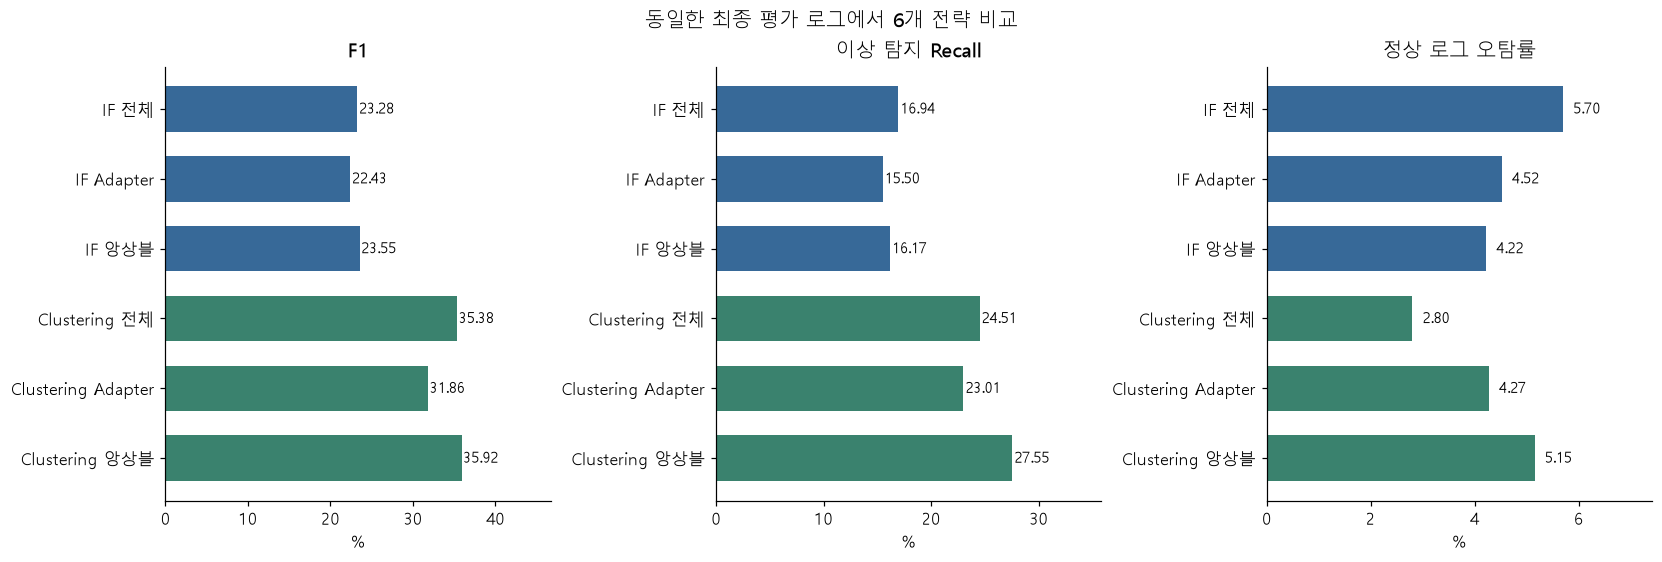

In [2]:
display(report.metrics_table(s['pooled']))
first = s['pooled'][0]
display(Markdown(f"평가 의사결정 **{first['n']:,}개**: 정상 {first['normal']:,}, 이상 {first['anomaly']:,}. "
                 f"전부 정상으로 예측해도 Accuracy는 **{first['always_normal_accuracy']:.2%}**다."))
report.metric_bars(s); plt.show()

### 결과 해석

F1 개선을 정상 오탐 증가와 함께 읽는다. Recall 상승만으로 개선이라고 확정하지 않는다.
행 수가 긴 점진적 악화/입력 중단이 합산 성능에 더 큰 영향을 준다. 아래 시나리오별 수치와 macro 평균도 함께 확인한다.

**현재 남은 큰 문제:** 개별 지연·컬럼 관계 탐지가 약하다. 선택 IF 앙상블의 정상 오탐은 두 시나리오에서 각각 약 44.9%, 38.4%다.
합산 정상 오탐 4.22%만 보고 모든 업무/시나리오에서 안정적이라고 해석하면 안 된다. 기존 운영 모델을 교체하지 않은 이유다.

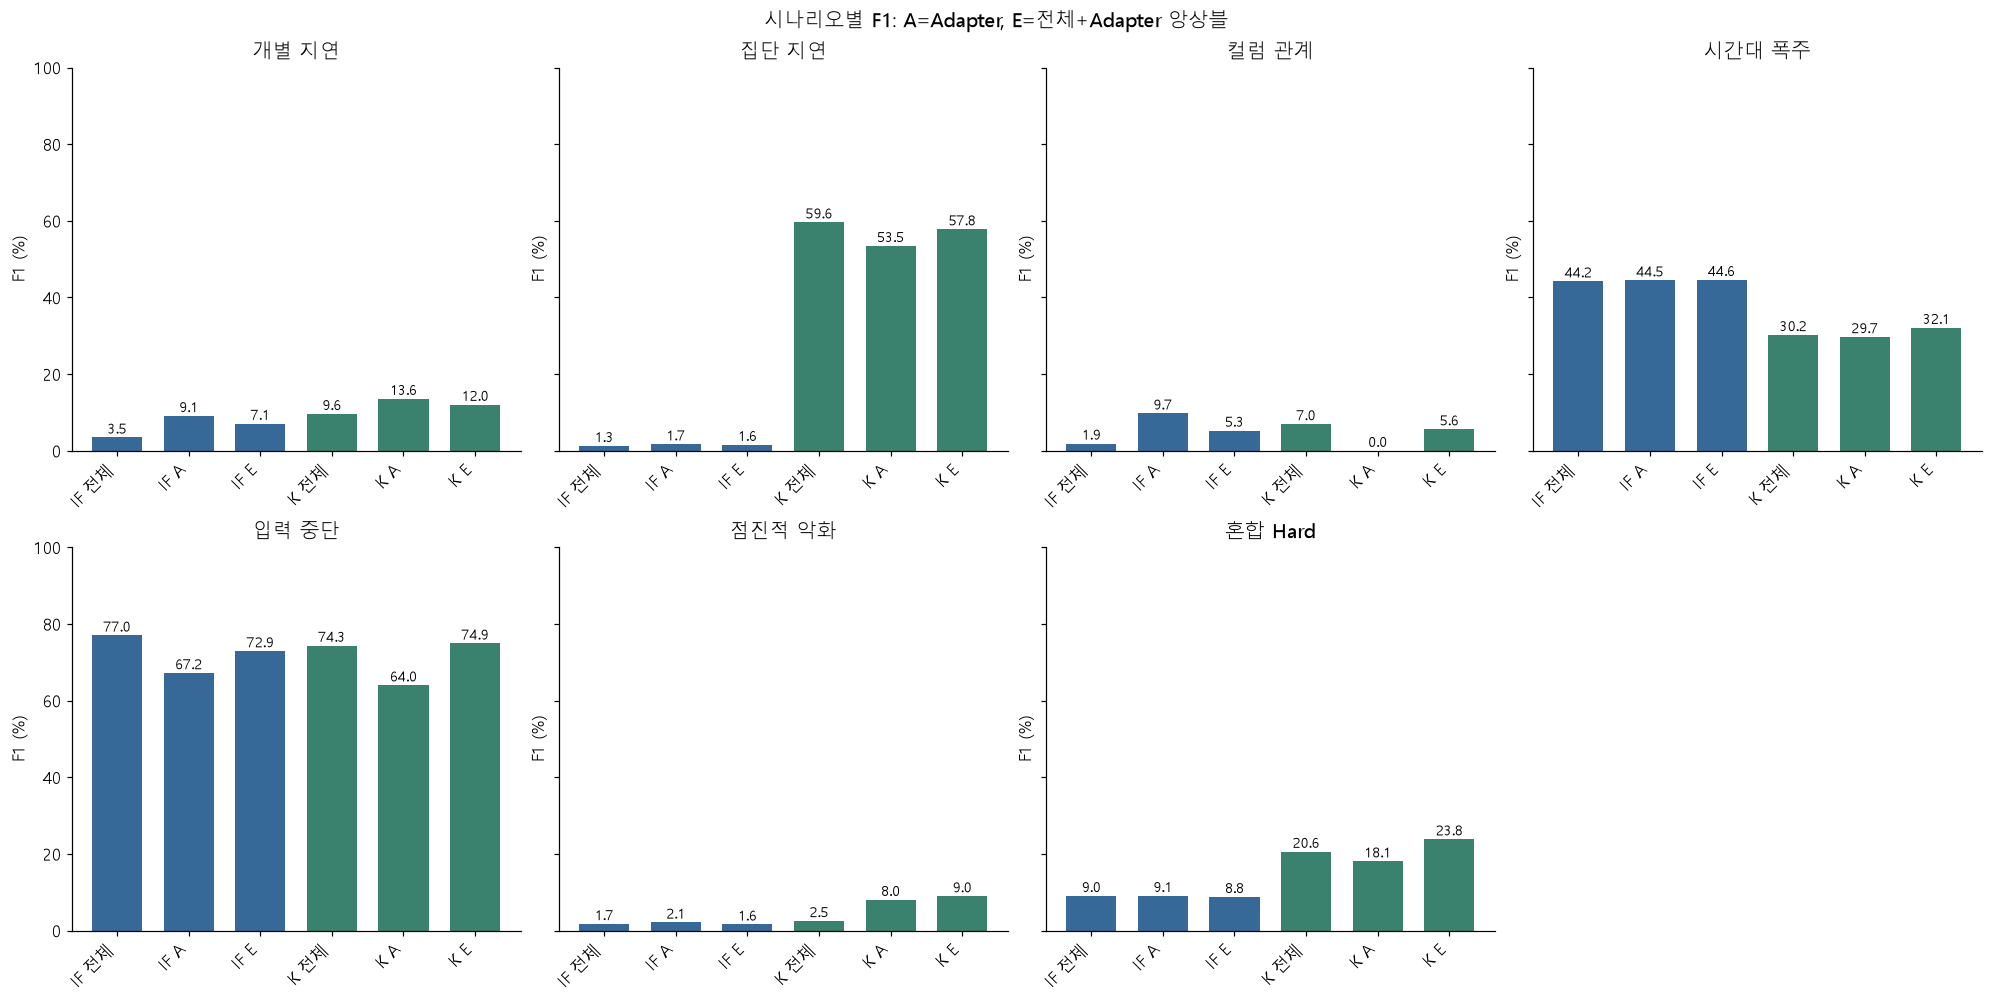

,Accuracy (%),Precision (%),Recall (%),F1 (%),정상 오탐률 (%)
IF 전체,68.87,27.56,20.71,21.60,21.82
IF Adapter,74.35,29.99,23.35,22.38,15.70
IF 앙상블,74.71,29.87,21.97,22.16,15.09
Clustering 전체,86.99,65.78,26.24,30.54,2.27
Clustering Adapter,84.56,38.83,24.95,28.12,4.83
Clustering 앙상블,81.13,40.89,30.47,31.90,9.69


,시나리오,모델,F1 (%),Recall (%),오탐 (%)
0,개별 지연,IF 전체,3.46,12.00,53.09
1,개별 지연,IF Adapter,9.08,29.40,47.39
2,개별 지연,IF 앙상블,7.07,21.64,44.89
3,개별 지연,Clustering 전체,9.62,5.21,0.29
4,개별 지연,Clustering Adapter,13.56,15.02,9.74
5,개별 지연,Clustering 앙상블,12.02,18.46,17.26
6,집단 지연,IF 전체,1.27,0.72,2.09
7,집단 지연,IF Adapter,1.70,0.94,1.68
8,집단 지연,IF 앙상블,1.57,0.85,1.34
9,집단 지연,Clustering 전체,59.61,65.82,9.80


In [3]:
report.scenario_bars(s); plt.show()
display(report.metrics_table(s['basic_macro']))
rows=[]
for d in s['datasets']:
    for metric in d['metrics']:
        rows.append({'시나리오': report.SCENARIO_NAMES[d['dataset']], '모델': report.LABELS[list(METHODS).index(metric['method'])],
                     'F1 (%)': metric['f1']*100, 'Recall (%)': metric['recall']*100,
                     '오탐 (%)': metric['normal_false_positive_rate']*100})
display(pd.DataFrame(rows).round(2))

## 2. 기존 5분 모델보다 무엇이 바뀌었나

아래 비교는 같은 평가셋, 같은 1분 라벨/의사결정 분모다. 피처, 일부 모델 설정, threshold, 앙상블 가중치가 바뀌었다.
최종 평가 성능을 보고 파라미터를 선택하지 않았다. 이 평가셋 자체는 과거에도 사용했으므로 새로운 블라인드 외부 검증은 아니다.

In [4]:
comparison=report.baseline_comparison(s)
display(comparison)
for i,row in comparison.iterrows():
    display(Markdown(f"- {i}: F1 {row['기존 F1 (%)']:.2f}% → {row['개선 F1 (%)']:.2f}% "
                     f"({row['F1 변화 (%p)']:+.2f}%p), 정상 오탐 {row['기존 오탐 (%)']:.2f}% → {row['개선 오탐 (%)']:.2f}%."))

,기존 F1 (%),개선 F1 (%),F1 변화 (%p),기존 오탐 (%),개선 오탐 (%)
IF 전체,22.01,23.28,1.27,2.99,5.70
IF Adapter,19.29,22.43,3.14,2.79,4.52
IF 앙상블,22.54,23.55,1.01,3.28,4.22
Clustering 전체,14.95,35.38,20.42,3.46,2.80
Clustering Adapter,17.52,31.86,14.34,4.50,4.27
Clustering 앙상블,17.44,35.92,18.48,4.29,5.15


- IF 전체: F1 22.01% → 23.28% (+1.27%p), 정상 오탐 2.99% → 5.70%.

- IF Adapter: F1 19.29% → 22.43% (+3.14%p), 정상 오탐 2.79% → 4.52%.

- IF 앙상블: F1 22.54% → 23.55% (+1.01%p), 정상 오탐 3.28% → 4.22%.

- Clustering 전체: F1 14.95% → 35.38% (+20.42%p), 정상 오탐 3.46% → 2.80%.

- Clustering Adapter: F1 17.52% → 31.86% (+14.34%p), 정상 오탐 4.50% → 4.27%.

- Clustering 앙상블: F1 17.44% → 35.92% (+18.48%p), 정상 오탐 4.29% → 5.15%.

## 3. 튜닝 절차와 확인용 집단

학습·점수 보정·threshold 기준은 서로 다른 정상 원본 실행/재생 에피소드다. 학습 원본은 전체 371만 행이 아니라 기존 정상 샘플 아카이브다.
정상 참고 집단에서 제외한 원본 템플릿으로 **새 검증 사례 1,440개**를 생성했다. 짝지은 정상 사례도 1,440개다.
탐색 720개·확인 720개로 나누고 동일 사례의 모든 분/정상 짝을 같은 집단에 둔다. 두 집단은 원본 템플릿 풀과 생성기를 공유한다.

트리/군집은 정상 데이터만 학습한다. 주입 라벨로 피처·하이퍼파라미터·운영점을 고르는 과정은 **라벨을 이용한 모델 선택**이며 전체 절차를 완전 비지도라고 부를 수는 없다.
목표는 6개 기본 시나리오 F1의 동일 가중 평균을 3개 전략에 다시 평균한 값이다. 각 전략의 **합산 정상 오탐률 5% 이하**인 후보만 선택한다.
확인용 결과는 설정을 확정한 뒤 1회 계산했으며 재선택에 사용하지 않았다. 확인 집단에서 오탐 제한을 넘으면 그 사실을 숨기지 않는다.

,집단,의사결정 수
0,train,10825
1,calibration,12987
2,threshold,11572


,split,normal_episodes,windows,independent_source_templates,adapters
0,train,120,10825,4448,15
1,calibration,144,12987,1952,18
2,threshold,128,11572,1917,16


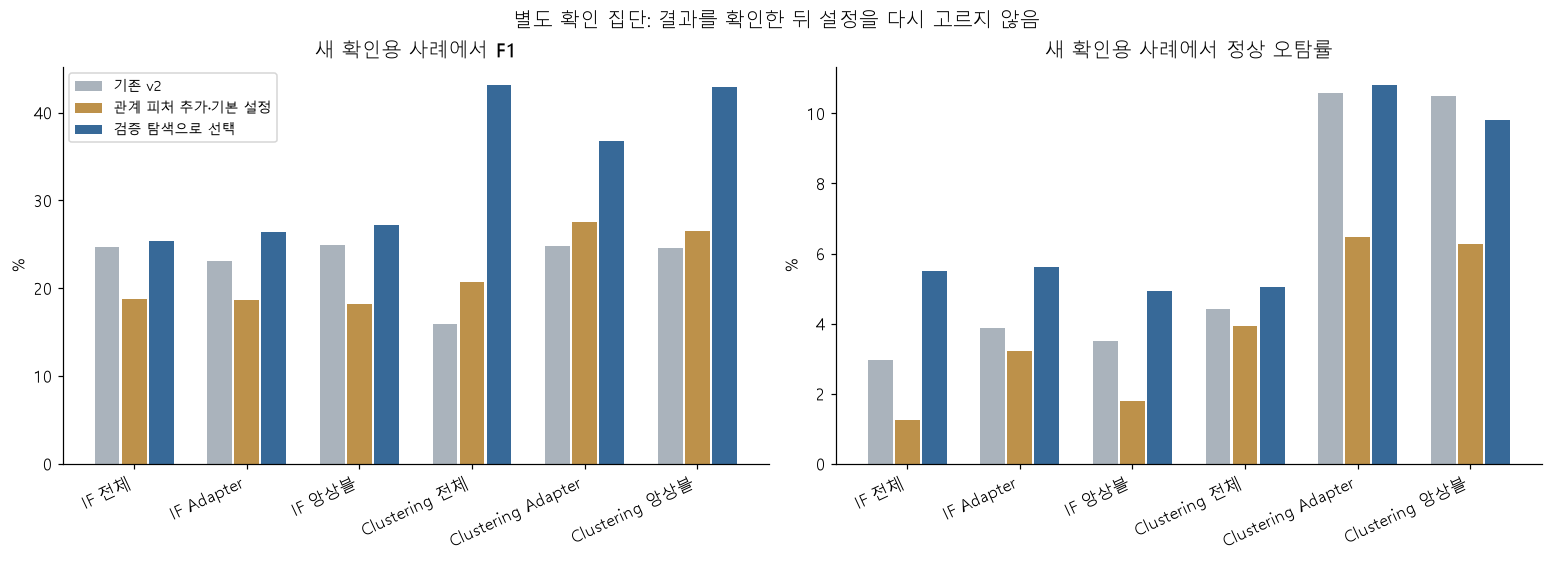

,Accuracy (%),Precision (%),Recall (%),F1 (%),정상 오탐률 (%)
IF 전체,82.27,39.50,18.71,25.39,5.51
IF Adapter,82.32,40.12,19.61,26.34,5.63
IF 앙상블,82.93,43.51,19.73,27.15,4.92
Clustering 전체,85.23,56.88,34.67,43.08,5.05
Clustering Adapter,80.50,38.53,35.21,36.80,10.80
Clustering 앙상블,82.30,44.71,41.32,42.95,9.82


**확인용 검증 제한:** IF 전체 오탐 5.51%, IF Adapter 오탐 5.63%, Clustering 전체 오탐 5.05%, Clustering Adapter 오탐 10.80%, Clustering 앙상블 오탐 9.82%

In [5]:
display(pd.DataFrame([{'집단':k,'의사결정 수':v} for k,v in prep['normal_reference_counts'].items()]))
display(pd.DataFrame(prep['normal_reference_episodes']))
report.confirmation_bars(validation); plt.show()
display(report.metrics_table(validation['features_tuned']['confirmation']['pooled']))
display(Markdown('**확인용 검증 제한:** ' + ', '.join(
    f"{report.LABELS[i]} 오탐 {x['normal_false_positive_rate']:.2%}" for i,x in enumerate(validation['features_tuned']['confirmation']['pooled'])
    if x['normal_false_positive_rate'] > .05) if any(x['normal_false_positive_rate']>.05 for x in validation['features_tuned']['confirmation']['pooled'])
    else '확인용 집단에서 여섯 전략 모두 합산 정상 오탐 5% 이하. 운영 환경 보장은 아님.'))

### 첫 실험에서 확인한 실패도 보존

v3는 기존 12개 피처를 여러 새 피처로 통째로 교체했다. IF 지연 탐지가 약해졌고 일부 Clustering Adapter의 오탐이 늘었다.
v4는 기존 피처를 후보로 유지하고 관계·시계열·축소 피처를 비교한다. 새 seed의 검증/확인 사례를 쓴다.
v3는 시나리오 macro 정상 오탐 2.5% 제한, v4는 합산 정상 오탐 5% 제한으로 목표도 다르다. 동일한 조건의 반복 실험이라고 주장하지 않는다.

In [6]:
old_validation=json.loads((ROOT/'reports/model_improvement_v3/validation_results.json').read_text(encoding='utf-8'))
display(report.metrics_table(old_validation['features_tuned']['confirmation']['pooled']))

,Accuracy (%),Precision (%),Recall (%),F1 (%),정상 오탐률 (%)
IF 전체,83.29,34.35,4.40,7.80,1.61
IF Adapter,82.93,29.00,4.30,7.48,2.01
IF 앙상블,83.14,32.40,4.53,7.95,1.81
Clustering 전체,83.37,41.37,8.36,13.91,2.27
Clustering Adapter,80.40,34.43,24.30,28.49,8.86
Clustering 앙상블,80.43,34.36,23.91,28.19,8.75


## 4. 실제 선택된 피처와 하이퍼파라미터

각 알고리즘에 피처 뷰 4개×모델 설정 3개=12개 모델 후보, 모델당 quantile 4개×전체 가중치 3개=12개 운영점을 동일하게 탐색했다.
IF는 128개 트리를 유지하고 max_samples=256/512/1024를 비교했다. v3에서는 256개 트리와 max_features=0.7도 비교했다.
Clustering은 K=6/12, 원거리/군집별 반경 보정 거리를 비교한다. batch_size=2048, n_init=5, max_iter=100, seed=42다.
신규 Adapter에는 전문 모델을 만들었다고 가정하지 않고 통합 모델로 fallback한다.

In [7]:
from model_improvement.refine import VIEWS
params=[]
for a,c in selection['families'].items():
    params.append({'모델':a,'선택 피처 뷰':c['view'],'피처 개수':len(VIEWS[c['view']]),
                   'trees':c['settings']['trees'] if a=='if' else None,
                   'max_samples':c['settings']['samples'] if a=='if' else None,
                   'K':c['settings']['k'] if a=='kmeans' else None,
                   '군집 반경 보정':c['settings']['radius_normalization'] if a=='kmeans' else None,
                   '정상 quantile':c['quantile'],'전체 가중치':c['global_weight'],'탐색 오탐 제한 만족':c['within_fpr_budget']})
display(pd.DataFrame(params))
for a,c in selection['families'].items(): display(Markdown(f"**{a} 입력:** `"+'`, `'.join(VIEWS[c['view']])+"`"))
display(pd.DataFrame([{'피처 계열':k,'의미':v} for k,v in DESCRIPTIONS.items()]))

,모델,선택 피처 뷰,피처 개수,trees,max_samples,K,군집 반경 보정,정상 quantile,전체 가중치,탐색 오탐 제한 만족
0,if,relational,16,128.0,1024.0,NaN,None,0.975,0.25,True
1,kmeans,temporal,18,NaN,NaN,6.0,True,0.999,0.75,True


**if 입력:** `log_arrivals`, `arrival_deviation`, `log_arrivals_5m`, `arrival_deviation_5m`, `log_p50_duration`, `log_p95_duration`, `p95_duration_relative`, `missing_duration`, `hour_sin`, `hour_cos`, `weekday_sin`, `weekday_cos`, `residual_max_1m`, `residual_p95_5m`, `residual_change`, `log_mean_count_5m`

**kmeans 입력:** `log_arrivals`, `arrival_deviation`, `log_arrivals_5m`, `arrival_deviation_5m`, `log_p50_duration`, `log_p95_duration`, `p95_duration_relative`, `missing_duration`, `hour_sin`, `hour_cos`, `weekday_sin`, `weekday_cos`, `arrival_dev_1m`, `arrival_dev_15m`, `zero_run`, `arrival_ewma`, `residual_change`, `log_max_duration_1m`

,피처 계열,의미
0,arrival_dev,현재 요청 수와 같은 요일 유형·시간대 과거 중앙값 차이 / (과거 P95+1)
1,arrival_logratio,log((현재 요청 수+1)/(같은 시간대 과거 중앙값+1))
2,zero_run,현재까지 연속으로 요청이 없던 분 수의 log1p; 에피소드 밖 과거는 추정하지 않음
3,arrival_ewma,"1분 요청 편차의 EWMA(alpha=0.2), 에피소드 시작에서 초기화"
4,arrival_change,1분 편차에서 직전 5분 편차 평균을 뺀 값
5,residual,log1p(실측 소요시간)와 학습 정상 집단 중앙값의 차이 / 학습 IQR(최소 0.15)
6,residual_change,5분 잔차 평균 - 15분 잔차 평균; 짧은 창에서 악화되면 양수
7,residual_ewma,완료된 로그의 1분 평균 잔차 EWMA(alpha=0.2); 완료 없음은 정상 잔차 0으로 완충
8,log_max_duration,1분 동안 실제 완료된 Process 중 최대 소요시간의 log1p
9,log_p95_duration,5분 동안 실제 완료된 Process 소요시간 P95의 log1p (분별 P95의 평균 아님)


### 피처의 근거와 한계

1·5·15분을 동시에 보면 짧은 급변과 지속적 변화가 함께 드러난다. 모델이 실제로 선택한 피처만 사용하며, 준비된 모든 피처를 모델이 본다고 해석하면 안 된다.
조건부 지연은 **Adapter+ProcessID+처리건수(log2 구간)** 정상 중앙값/IQR을 사용한다. 원본 학습 30행 미만이면 Adapter+건수 → Adapter+ProcessID → Adapter → 전체로 내려간다.
희소 집단의 참고값은 부정확할 수 있다. 작은 IQR은 최소 0.15로 제한한다. ProcessID는 참고값 조회에만 쓰고 ID 자체를 벡터에 넣지 않는다.
EWMA alpha=0.2는 변화 이력을 피처화하기 위한 고정 값이다. 정규분포 가정의 3-sigma 제어 한계를 적용한 것은 아니다.

## 5. Threshold는 어디서 나오나

각 모델의 별도 정상 threshold 참고 집단 점수에서 선택 quantile을 취한다. sklearn의 `predict(-1)`/contamination을 그대로 쓰지 않는다.
IF 원점수는 `-score_samples`라 높을수록 희귀하다. Clustering 원점수는 가장 가까운 정상 군집 중심까지의 거리이며 선택된 경우 해당 군집 정상 P95 반경으로 나눈다.
점수 보정은 정상 calibration의 중앙값과 (P95−중앙값)으로 한다. 앙상블은 보정된 전체·Adapter 점수를 선택 가중치로 결합하고 **결합 점수 자체의 threshold도 정상 집단에서 따로 계산**한다.

최종 margin = 보정 점수 − 해당 경로 threshold. **0 초과만 경보**, 0 이하는 정상 판정이다. margin 크기가 모델 간 공통 확률은 아니다.

,algorithm,route,quantile,global_weight,raw_threshold,normalized_threshold,ensemble_threshold,effective_k
0,if,GLOBAL,0.975,0.25,0.61675,1.36362,1.36362,NaN
1,if,DB.READER,0.975,0.25,0.66402,1.14001,1.25303,NaN
2,if,DB.WRITER,0.975,0.25,0.67715,1.13914,1.15447,NaN
3,if,FILE.READER,0.975,0.25,0.63562,1.09572,1.18042,NaN
4,if,FILE.WRITER,0.975,0.25,0.65764,1.62793,1.62293,NaN
5,if,SERVICE.EXECUTOR,0.975,0.25,0.64040,1.14059,1.27536,NaN
6,kmeans,GLOBAL,0.999,0.75,1.98423,3.39716,3.39716,6.0
7,kmeans,DB.READER,0.999,0.75,2.44964,5.56517,3.91109,6.0
8,kmeans,DB.WRITER,0.999,0.75,2.36000,7.89353,2.69324,6.0
9,kmeans,FILE.READER,0.999,0.75,1.38841,3.46447,3.41348,6.0


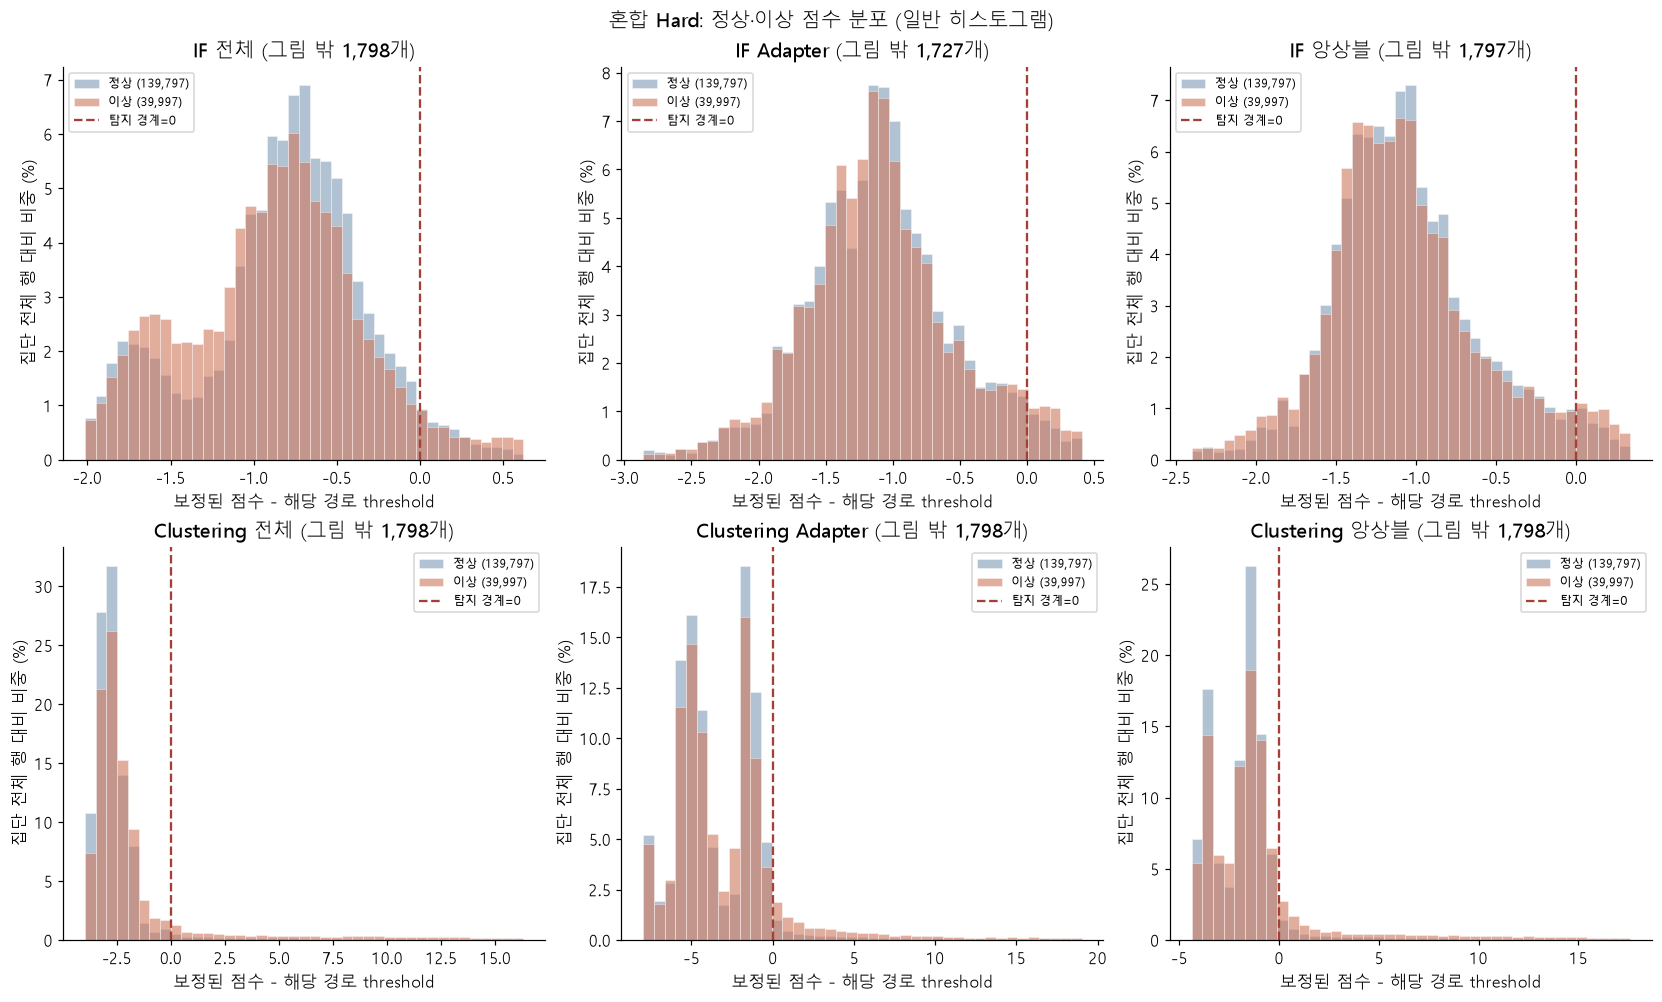

In [8]:
thresholds=pd.DataFrame(s['thresholds'])
display(thresholds[['algorithm','route','quantile','global_weight','raw_threshold','normalized_threshold','ensemble_threshold','effective_k']].round(5))
report.score_histograms('mixed_hard'); plt.show()

### 히스토그램 읽는 법

일반 막대가 정상·이상 점수의 분포다. 붉은 점선 오른쪽 이상 막대는 TP, 오른쪽 정상 막대는 FP다. 왼쪽 이상 막대는 놓친 이상이다.
가독성을 위해 합산 점수 P0.5~P99.5 범위로 그림만 제한하고 그림 밖 수를 각 패널에 표기했다. 지표 계산은 전체 행을 사용한다.
막대 높이는 표시 구간만 재정규화하지 않고 각 집단 전체 행 수 대비 비중이다. 정상과 이상이 겹친다면 단일 threshold로 완벽하게 나누기 어렵다.

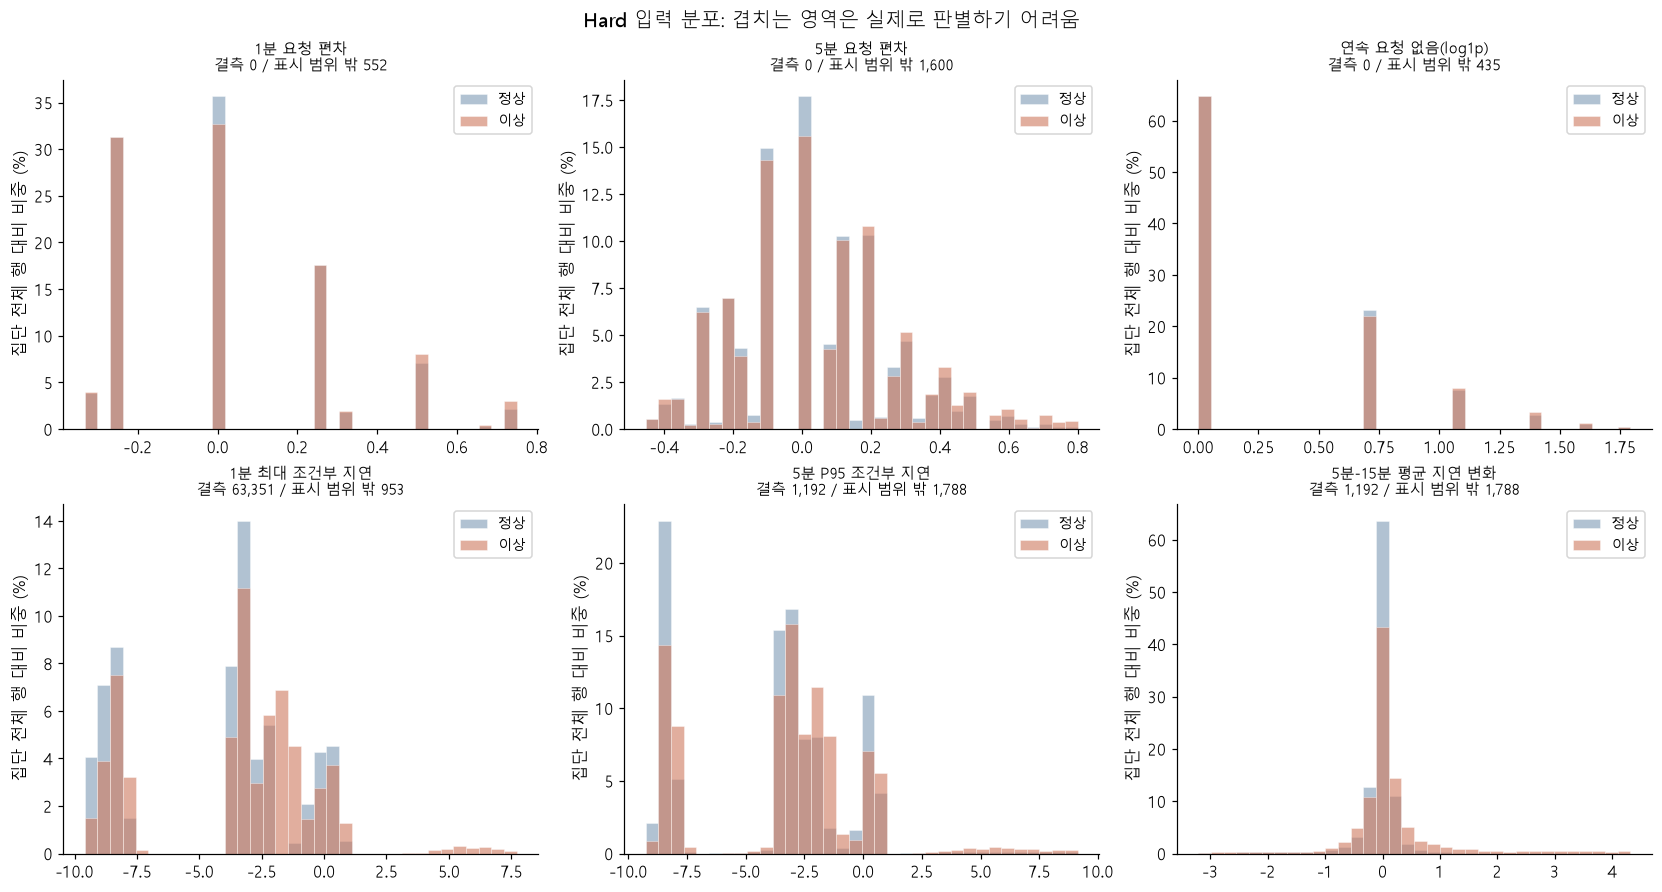

In [9]:
report.input_histograms(); plt.show()

## 6. IF와 Clustering은 실제로 무엇이 다른가

IF는 여러 피처 조합이 정상 데이터에서 얼마나 쉽게 분리되는지 본다. Clustering은 어느 정상 패턴(중심)에 가장 가깝고 그 패턴에서 얼마나 떨어졌는지 본다.
아래는 **두 알고리즘의 앙상블끼리** 비교한다. 'IF만 탐지'와 'Clustering만 탐지'가 실제 보완 영역이다.
정상 구간에도 같은 그림을 보이며, 정상에서만 늘어난 단독 경보를 장점으로 해석하지 않는다. 단순 OR 결합 모델을 새로 운영한 결과가 아니다.

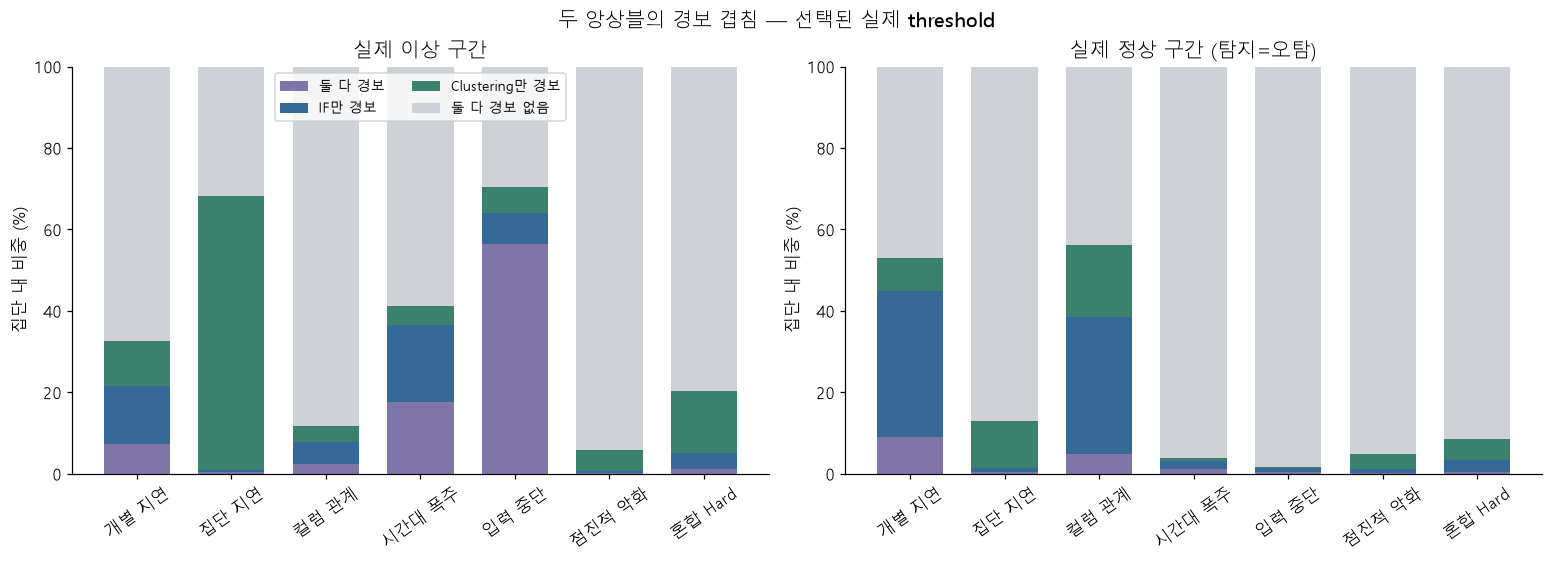

In [10]:
report.overlap_bars(roles); plt.show()

### 정상 오탐 예산을 맞춘 보조 비교

서로 다른 운영점 때문에 역할 차이가 생기는지 점검한다. **확인용 정상 짝의 점수만** 사용해 각 전략을 오탐 1%에 맞춘 별도 진단 경계를 만들었다.
이 경계로 최종 평가 결과를 다시 비교하지만 모델/선택 threshold를 변경하지 않는다. 다른 분포의 최종 정상 로그에서도 정확히 1%를 보장하는 것은 아니다.

,Accuracy (%),Precision (%),Recall (%),F1 (%),정상 오탐률 (%)
IF 전체,84.52,68.35,12.68,21.40,1.17
IF Adapter,84.30,71.91,8.95,15.91,0.70
IF 앙상블,84.37,70.94,9.94,17.43,0.81
Clustering 전체,85.08,63.51,23.96,34.79,2.74
Clustering Adapter,83.35,47.93,2.99,5.62,0.65
Clustering 앙상블,83.36,49.40,6.70,11.80,1.37


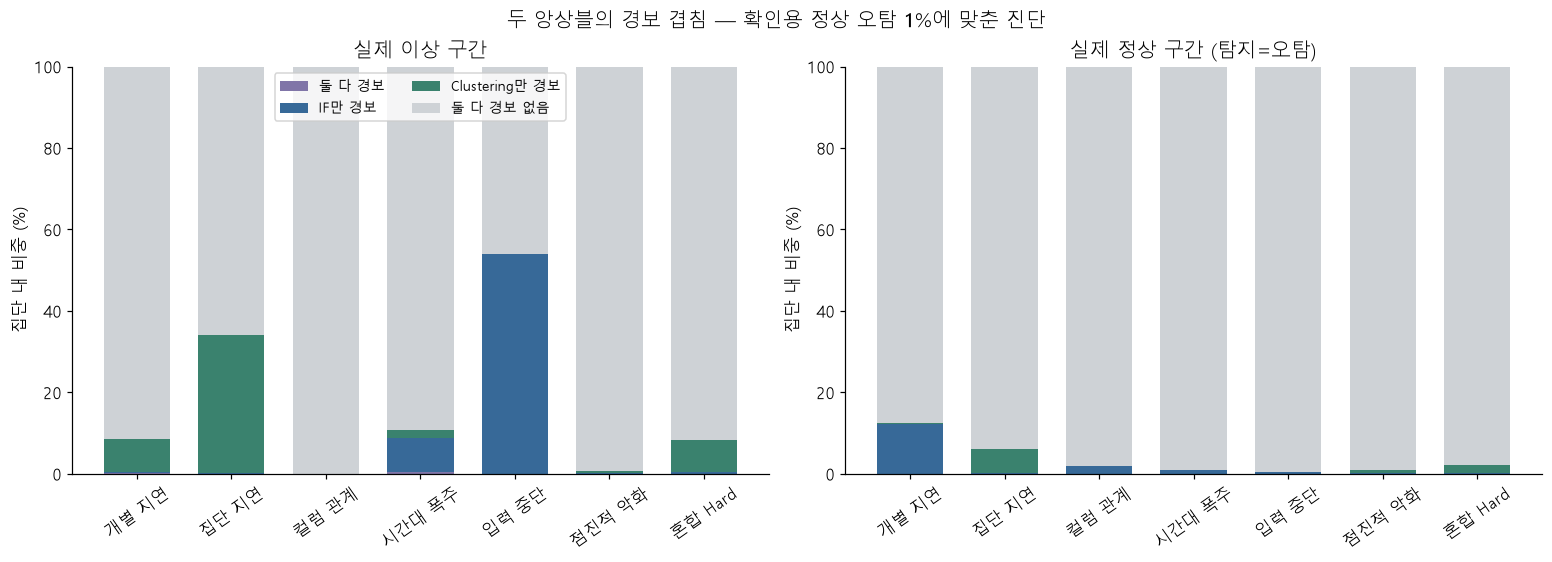

,left,right,metric,low_95,median,high_95,repetitions,unit,limitation
0,kmeans_ensemble,if_ensemble,pooled F1 difference (left-right),0.1209,0.1238,0.1265,400,synthetic case with observed+normal pair; stratified by scenario,"Case sampling uncertainty only; no training-seed, source-template or real-world domain..."
1,if_ensemble,if_global,pooled F1 difference (left-right),0.0009,0.0026,0.0044,400,synthetic case with observed+normal pair; stratified by scenario,"Case sampling uncertainty only; no training-seed, source-template or real-world domain..."
2,kmeans_ensemble,kmeans_global,pooled F1 difference (left-right),0.0041,0.0054,0.0068,400,synthetic case with observed+normal pair; stratified by scenario,"Case sampling uncertainty only; no training-seed, source-template or real-world domain..."
3,if_adapter,if_global,pooled F1 difference (left-right),-0.0108,-0.0085,-0.0060,400,synthetic case with observed+normal pair; stratified by scenario,"Case sampling uncertainty only; no training-seed, source-template or real-world domain..."
4,kmeans_adapter,kmeans_global,pooled F1 difference (left-right),-0.0380,-0.0352,-0.0321,400,synthetic case with observed+normal pair; stratified by scenario,"Case sampling uncertainty only; no training-seed, source-template or real-world domain..."


In [11]:
display(report.metrics_table(roles['matched_budget_pooled']))
report.overlap_bars(roles, matched=True); plt.show()
display(pd.DataFrame(roles['paired_bootstrap']).round(4))

95% 구간은 원본/정상 짝을 묶은 사례 단위로 시나리오별 재표본추출 400회에서 계산했다. 0을 포함하면 이 샘플링 수준에서 우열이 분명하지 않다.
같은 원본 템플릿 반복, 학습 seed 변동, 실제 운영 환경 차이를 모두 반영하는 신뢰구간은 아니다.

### 피처 차이와 알고리즘 차이 구분

최종 IF와 Clustering은 선택 피처가 다르다. 앞의 차이는 알고리즘뿐 아니라 **피처·설정·운영점 차이가 함께 만든 결과**다.
따라서 동일한 관계 피처 16개, 기본 모델 설정, 동일 정상 참고 집단으로 두 모델을 다시 비교하는 통제 실험을 추가했다.
확인용 정상 점수로 오탐 예산을 맞춘 진단이며 최종 라벨로 새 모델을 선택하거나 승격한 것이 아니다.
역할 결론은 이번 구성/데이터에서 관측된 범위에 한정한다.

In [12]:
display(report.metrics_table(roles['common_view_diagnostic']['matched_pooled']))
common_rows=[]
for d in roles['datasets']:
    for i in (2,5):
        m=d['common_view_matched_metrics'][i]
        common_rows.append({'시나리오':report.SCENARIO_NAMES[d['dataset']], '모델':report.LABELS[i],
                            '같은 피처 F1 (%)':m['f1']*100,'같은 피처 Recall (%)':m['recall']*100,
                            '같은 피처 오탐 (%)':m['normal_false_positive_rate']*100})
display(pd.DataFrame(common_rows).round(2))

,Accuracy (%),Precision (%),Recall (%),F1 (%),정상 오탐률 (%)
IF 전체,83.98,61.80,9.26,16.11,1.14
IF Adapter,83.14,31.95,1.34,2.57,0.57
IF 앙상블,83.17,42.31,3.73,6.85,1.01
Clustering 전체,83.15,44.51,5.77,10.22,1.43
Clustering Adapter,82.48,35.84,6.95,11.64,2.48
Clustering 앙상블,82.00,32.09,7.48,12.13,3.15


,시나리오,모델,같은 피처 F1 (%),같은 피처 Recall (%),같은 피처 오탐 (%)
0,개별 지연,IF 앙상블,0.84,0.90,10.21
1,개별 지연,Clustering 앙상블,7.54,8.73,11.25
2,집단 지연,IF 앙상블,0.21,0.11,0.24
3,집단 지연,Clustering 앙상블,36.33,32.34,8.15
4,컬럼 관계,IF 앙상블,0.32,0.27,13.64
5,컬럼 관계,Clustering 앙상블,4.69,4.00,13.34
6,시간대 폭주,IF 앙상블,15.25,8.70,0.62
7,시간대 폭주,Clustering 앙상블,2.42,1.24,0.20
8,입력 중단,IF 앙상블,25.44,14.81,0.21
9,입력 중단,Clustering 앙상블,6.17,3.24,0.22


## 7. 전체 모델과 Adapter 모델의 역할

전체 모델은 폭넓은 정상 패턴과 새로운 Adapter fallback을 담당한다. Adapter 모델은 같은 역할 집단의 정상 패턴만 학습하므로 전체에서 묻히는 이상을 찾을 수 있다.
반대로 Adapter 학습 집단이 좁으면 다른 정상 Process의 패턴도 이상으로 볼 수 있다. 전문 모델이 항상 더 좋거나 앙상블이 반드시 이기는 것은 아니다.
아래는 **동일한 전문 모델 지원 집단에서만** 세 전략을 비교하고, Adapter별 결과도 분리한다.

,adapter,train,calibration,threshold,expert_available,reason
0,DATA.DECRYPTOR,0,726,0,False,train<500; threshold<100; train_source_workflows<20; calibration_source_workflows<20; ...
1,DATA.ENCRYPTOR,0,722,0,False,train<500; threshold<100; train_source_workflows<20; calibration_source_workflows<20; ...
2,DATA.MAPPER,725,723,725,False,train_source_workflows<20; calibration_source_workflows<20; threshold_source_workflows<20
3,DATA.TRANSFORMER,726,723,723,False,train_source_workflows<20; calibration_source_workflows<20; threshold_source_workflows<20
4,DB.DELETER,719,0,726,False,calibration<100; train_source_workflows<20; calibration_source_workflows<20; threshold...
5,DB.EXECUTOR,723,724,724,False,train_source_workflows<20
6,DB.READER,721,717,726,True,supported
7,DB.UPDATER,724,723,719,False,train_source_workflows<20; calibration_source_workflows<20; threshold_source_workflows<20
8,DB.WRITER,723,722,724,True,supported
9,FILE.EXECUTOR,0,717,727,False,train<500; train_source_workflows<20; calibration_source_workflows<20; threshold_sourc...


,Accuracy (%),Precision (%),Recall (%),F1 (%),정상 오탐률 (%)
IF 전체,75.60,20.19,9.78,13.17,9.03
IF Adapter,77.07,20.37,7.26,10.71,6.63
IF 앙상블,77.78,24.65,8.44,12.57,6.02
Clustering 전체,81.44,52.33,21.98,30.96,4.68
Clustering Adapter,78.52,37.10,19.37,25.45,7.67
Clustering 앙상블,78.56,40.22,27.26,32.49,9.46


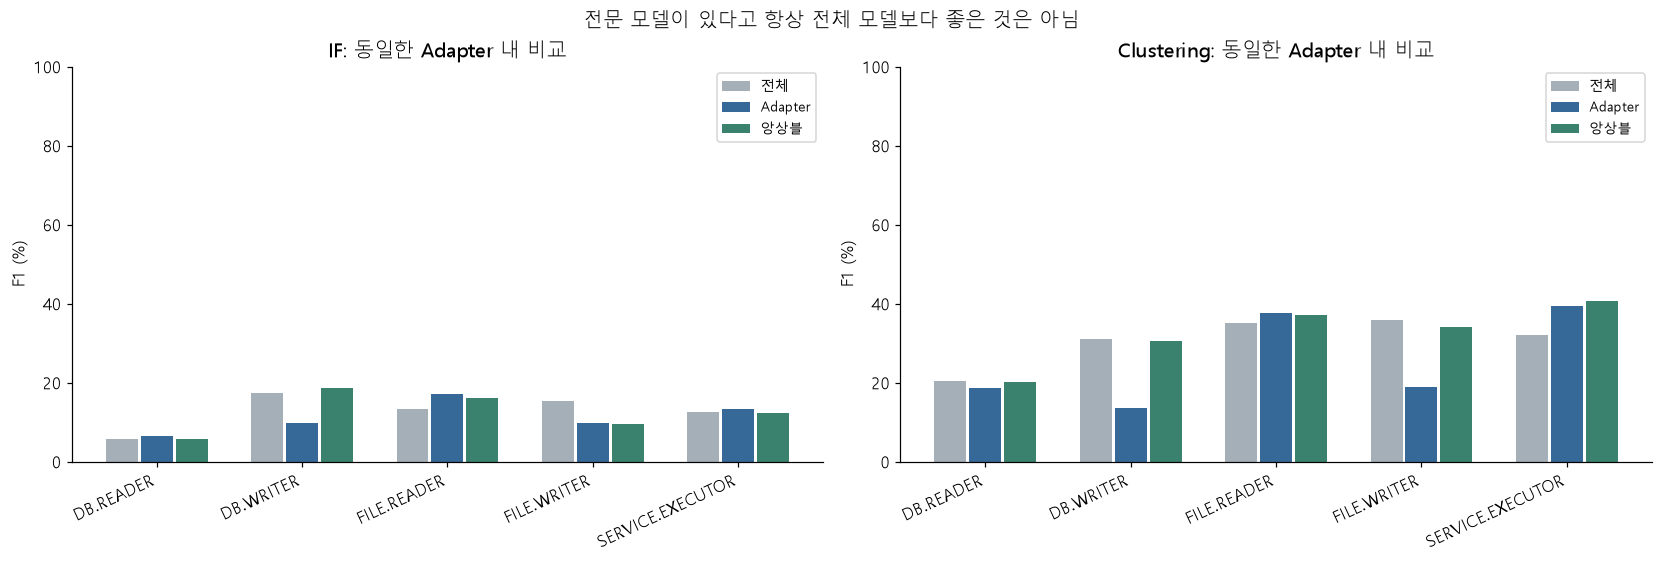

평가 행의 전문 모델 지원 비중: **50.56%**. 미지원에서는 세 전략이 같은 전체 모델 점수로 처리된다.

In [13]:
support=pd.DataFrame(s['support'])
display(support[['adapter','train','calibration','threshold','expert_available','reason']])
display(report.supported_table(s))
report.adapter_bars(roles); plt.show()
coverage=sum(d['coverage']*(2*d['metrics'][0]['n']/2) for d in s['datasets'])/sum(d['metrics'][0]['n'] for d in s['datasets'])
display(Markdown(f"평가 행의 전문 모델 지원 비중: **{coverage:.2%}**. 미지원에서는 세 전략이 같은 전체 모델 점수로 처리된다."))

## 8. Clustering 정상 패턴과 탐지 근거

군집은 실패 유형 정답이 아니라 정상 학습 로그의 대표 패턴이다. cluster 번호 순서는 의미/심각도 순위가 아니다.
반경은 정상 calibration에서 해당 중심에 가까운 로그들의 P95 거리다. 30행 미만이면 전체 반경을 쓴다. CBLOF를 그대로 구현한 것이 아니다.

In [14]:
centers=[]
for c in roles['clusters']:
    selected_features={k:c['features'].get(k) for k in ('log_arrivals','arrival_deviation','p95_duration_relative','zero_run','residual_change')}
    centers.append({'경로':c['route'],'군집':c['cluster'],'학습 창':c['train_windows'],
                     'P95 반경':c['radius_p95'],**selected_features})
center_frame=pd.DataFrame(centers).rename(columns={'log_arrivals':'요청 수(log1p)','arrival_deviation':'5분 요청 편차',
    'p95_duration_relative':'기존 집단 대비 P95 지연','zero_run':'연속 요청 없음(log1p)','residual_change':'지연 변화'})
for route,table in center_frame.groupby('경로',sort=False):
    display(Markdown(f'### {route} 정상 중심'))
    display(table.drop(columns='경로').round(3))

### GLOBAL 정상 중심

,군집,학습 창,P95 반경,요청 수(log1p),5분 요청 편차,기존 집단 대비 P95 지연,연속 요청 없음(log1p),지연 변화
0,0,1695,2.565,1.524,-0.174,-0.019,0.012,-0.0
1,1,2265,2.538,2.326,0.283,-0.001,0.046,-0.0
2,2,89,2.626,2.127,0.079,-5.196,0.113,0.0
3,3,1867,2.848,2.072,0.043,-0.169,0.021,-0.0
4,4,2439,2.928,1.611,-0.150,-0.028,0.863,-0.0
5,5,2470,2.012,2.147,0.009,0.086,0.043,-0.0


### DB.READER 정상 중심

,군집,학습 창,P95 반경,요청 수(log1p),5분 요청 편차,기존 집단 대비 P95 지연,연속 요청 없음(log1p),지연 변화
6,0,171,2.220,1.980,-0.095,0.176,0.044,0.0
7,1,131,2.220,2.109,0.180,-0.225,0.072,-0.0
8,2,88,1.969,2.323,0.082,-1.092,0.069,0.0
9,3,118,2.453,1.635,-0.180,-0.051,0.757,-0.0
10,4,74,1.961,2.125,0.092,0.019,0.092,0.0
11,5,139,2.220,2.303,0.189,0.060,0.053,-0.0


### DB.WRITER 정상 중심

...

,군집,학습 창,P95 반경,요청 수(log1p),5분 요청 편차,기존 집단 대비 P95 지연,연속 요청 없음(log1p),지연 변화
18,0,93,4.003,2.185,0.116,-0.182,0.016,0.0
19,1,177,3.978,1.717,-0.001,0.203,0.008,-0.0
20,2,155,3.978,1.370,-0.174,0.177,0.862,-0.0
21,3,85,3.881,1.777,-0.175,-0.037,0.376,0.0
22,4,119,1.720,2.171,0.145,0.362,0.092,0.0
23,5,93,3.980,1.917,0.127,-0.238,0.136,-0.0


### FILE.WRITER 정상 중심

,군집,학습 창,P95 반경,요청 수(log1p),5분 요청 편차,기존 집단 대비 P95 지연,연속 요청 없음(log1p),지연 변화
24,0,113,11.844,1.863,0.106,-0.195,0.040,-0.0
25,1,175,11.832,2.339,0.172,0.135,0.027,-0.0
26,2,87,11.832,1.508,-0.150,0.143,0.747,0.0
27,3,182,11.832,1.913,-0.118,0.139,0.260,-0.0
28,4,122,11.832,1.988,0.091,0.193,0.055,-0.0
29,5,39,7.321,1.223,-0.225,-0.298,0.957,0.0


### SERVICE.EXECUTOR 정상 중심

,군집,학습 창,P95 반경,요청 수(log1p),5분 요청 편차,기존 집단 대비 P95 지연,연속 요청 없음(log1p),지연 변화
30,0,103,2.005,1.345,-0.233,-0.028,0.980,0.0
31,1,132,2.008,2.304,0.277,0.001,0.087,-0.0
32,2,101,1.924,2.176,0.125,-4.453,0.082,0.0
33,3,116,2.041,1.737,0.038,0.053,0.144,0.0
34,4,119,2.008,2.032,0.023,0.001,0.137,0.0
35,5,147,2.008,1.926,-0.054,0.000,0.118,-0.0


### 실제 탐지·미탐지·오탐 사례

각 평가셋/범주에서 첫 번째 해당 행을 사용했다. 최고 점수/성공한 사례만 골라 보여주지 않는다.
IF: 한 피처를 학습 중앙값으로 바꿨을 때 점수가 얼마나 낮아지는지 확인한 **민감도**다. SHAP/인과적 원인 분석은 아니다.
Clustering: 가장 가까운 중심까지의 **제곱 거리 기여 비중**이다. 운영 장애의 원인을 확정하는 설명은 아니다.
아래 정리에서 margin이 양수면 경보이며, 설명의 상위 피처가 실제 관측 변화와 맞는지 확인한다.

In [15]:
example_rows=[]
for e in roles['examples']:
    for detail in e['explanations']:
        top=detail['top_features'][:3]
        text=', '.join(f"{x['feature']} ({x.get('score_drop',x.get('distance_share')):.3f})" for x in top)
        example_rows.append({'평가셋':report.SCENARIO_NAMES[e['scenario']],'범주':e['category'],'사례':e['case_index'],
                              'Adapter':e['adapter'],'모델':detail['algorithm'],'경로':detail['route'],
                              'IF 앙상블 margin':e['margins']['if_ensemble'],'Clustering 앙상블 margin':e['margins']['kmeans_ensemble'],
                              '주요 피처 (IF=점수 감소, K=거리 비중)':text})
example_frame=pd.DataFrame(example_rows).round(4)
for dataset,table in example_frame.groupby('평가셋',sort=False):
    display(Markdown(f'### {dataset} 판단 근거'))
    display(table.drop(columns='평가셋'))

### 개별 지연 판단 근거

,범주,사례,Adapter,모델,경로,IF 앙상블 margin,Clustering 앙상블 margin,"주요 피처 (IF=점수 감소, K=거리 비중)"
0,if_only,2707,DB.UPDATER,if,GLOBAL,0.1015,-0.1636,"log_arrivals_5m (0.497), log_arrivals (0.394), log_p95_duration (0.359)"
1,if_only,2707,DB.UPDATER,kmeans,GLOBAL,0.1015,-0.1636,"p95_duration_relative (0.758), arrival_ewma (0.053), log_arrivals_5m (0.028)"
2,kmeans_only,4349,SERVICE.EXECUTOR,if,GLOBAL,-0.7300,1.4104,"log_arrivals (0.455), log_arrivals_5m (0.418), log_p95_duration (0.340)"
3,kmeans_only,4349,SERVICE.EXECUTOR,if,SERVICE.EXECUTOR,-0.7300,1.4104,"log_arrivals (0.536), log_arrivals_5m (0.437), weekday_sin (0.147)"
4,kmeans_only,4349,SERVICE.EXECUTOR,kmeans,GLOBAL,-0.7300,1.4104,"p95_duration_relative (0.875), log_arrivals (0.022), log_arrivals_5m (0.022)"
5,kmeans_only,4349,SERVICE.EXECUTOR,kmeans,SERVICE.EXECUTOR,-0.7300,1.4104,"zero_run (0.428), p95_duration_relative (0.153), log_arrivals_5m (0.089)"
6,both,3553,FILE.READER,if,GLOBAL,0.2178,4.2692,"log_arrivals_5m (0.431), log_arrivals (0.418), log_p95_duration (0.295)"
7,both,3553,FILE.READER,if,FILE.READER,0.2178,4.2692,"log_arrivals (0.557), log_arrivals_5m (0.486), residual_max_1m (0.394)"
8,both,3553,FILE.READER,kmeans,GLOBAL,0.2178,4.2692,"p95_duration_relative (0.625), arrival_ewma (0.082), log_arrivals_5m (0.043)"
9,both,3553,FILE.READER,kmeans,FILE.READER,0.2178,4.2692,"log_max_duration_1m (0.227), p95_duration_relative (0.197), log_p95_duration (0.197)"


### 집단 지연 판단 근거

,범주,사례,Adapter,모델,경로,IF 앙상블 margin,Clustering 앙상블 margin,"주요 피처 (IF=점수 감소, K=거리 비중)"
14,if_only,1651,DB.WRITER,if,GLOBAL,0.0051,-2.0700,"log_arrivals_5m (0.454), log_p95_duration (0.327), log_arrivals (0.320)"
15,if_only,1651,DB.WRITER,if,DB.WRITER,0.0051,-2.0700,"log_arrivals_5m (0.582), log_arrivals (0.566), hour_sin (0.207)"
16,if_only,1651,DB.WRITER,kmeans,GLOBAL,0.0051,-2.0700,"residual_change (0.460), log_arrivals (0.110), log_arrivals_5m (0.110)"
17,if_only,1651,DB.WRITER,kmeans,DB.WRITER,0.0051,-2.0700,"residual_change (0.379), log_arrivals (0.180), log_arrivals_5m (0.180)"
18,kmeans_only,783,DATA.TRANSFORMER,if,GLOBAL,-1.7689,0.0551,"residual_max_1m (0.166), weekday_sin (0.135), log_p95_duration (0.124)"
19,kmeans_only,783,DATA.TRANSFORMER,kmeans,GLOBAL,-1.7689,0.0551,"p95_duration_relative (0.516), residual_change (0.381), log_arrivals_5m (0.017)"
20,both,3695,DB.READER,if,GLOBAL,0.0172,0.0111,"missing_duration (1.068), log_arrivals_5m (1.003), log_arrivals (0.615)"
21,both,3695,DB.READER,if,DB.READER,0.0172,0.0111,"log_arrivals_5m (0.443), log_arrivals (0.320), arrival_deviation (0.214)"
22,both,3695,DB.READER,kmeans,GLOBAL,0.0172,0.0111,"missing_duration (0.731), log_arrivals (0.076), log_arrivals_5m (0.076)"
23,both,3695,DB.READER,kmeans,DB.READER,0.0172,0.0111,"missing_duration (0.688), log_arrivals (0.096), log_arrivals_5m (0.096)"


### 컬럼 관계 판단 근거

...

,범주,사례,Adapter,모델,경로,IF 앙상블 margin,Clustering 앙상블 margin,"주요 피처 (IF=점수 감소, K=거리 비중)"
62,if_only,3802,DATA.ENCRYPTOR,if,GLOBAL,0.8254,-0.0422,"missing_duration (1.086), log_arrivals_5m (0.909), log_arrivals (0.818)"
63,if_only,3802,DATA.ENCRYPTOR,kmeans,GLOBAL,0.8254,-0.0422,"missing_duration (0.735), log_arrivals (0.076), log_arrivals_5m (0.076)"
64,kmeans_only,2216,FILE.WRITER,if,GLOBAL,-0.1575,0.5811,"log_arrivals_5m (0.835), missing_duration (0.797), log_arrivals (0.717)"
65,kmeans_only,2216,FILE.WRITER,if,FILE.WRITER,-0.1575,0.5811,"log_arrivals_5m (0.853), log_arrivals (0.691), arrival_deviation_5m (0.276)"
66,kmeans_only,2216,FILE.WRITER,kmeans,GLOBAL,-0.1575,0.5811,"missing_duration (0.702), log_arrivals (0.073), log_arrivals_5m (0.073)"
67,kmeans_only,2216,FILE.WRITER,kmeans,FILE.WRITER,-0.1575,0.5811,"missing_duration (0.706), log_arrivals (0.041), log_arrivals_5m (0.041)"
68,both,3802,DATA.ENCRYPTOR,if,GLOBAL,0.8254,0.0116,"missing_duration (1.086), log_arrivals_5m (0.909), log_arrivals (0.818)"
69,both,3802,DATA.ENCRYPTOR,kmeans,GLOBAL,0.8254,0.0116,"missing_duration (0.718), log_arrivals (0.075), log_arrivals_5m (0.075)"
70,missed,3802,DATA.ENCRYPTOR,if,GLOBAL,-2.2161,-3.3039,"p95_duration_relative (0.469), weekday_sin (0.082), log_p95_duration (0.046)"
71,missed,3802,DATA.ENCRYPTOR,kmeans,GLOBAL,-2.2161,-3.3039,"p95_duration_relative (0.561), log_arrivals (0.063), log_arrivals_5m (0.063)"


### 점진적 악화 판단 근거

,범주,사례,Adapter,모델,경로,IF 앙상블 margin,Clustering 앙상블 margin,"주요 피처 (IF=점수 감소, K=거리 비중)"
74,if_only,2161,FILE.WRITER,if,GLOBAL,0.4372,-1.8576,"residual_p95_5m (0.491), p95_duration_relative (0.458), log_arrivals (0.316)"
75,if_only,2161,FILE.WRITER,if,FILE.WRITER,0.4372,-1.8576,"log_arrivals (0.952), log_arrivals_5m (0.874), arrival_deviation (0.459)"
76,if_only,2161,FILE.WRITER,kmeans,GLOBAL,0.4372,-1.8576,"p95_duration_relative (0.565), log_arrivals (0.122), log_arrivals_5m (0.122)"
77,if_only,2161,FILE.WRITER,kmeans,FILE.WRITER,0.4372,-1.8576,"log_p95_duration (0.300), log_p50_duration (0.300), p95_duration_relative (0.299)"
78,kmeans_only,785,FILE.WRITER,if,GLOBAL,-0.8813,0.5242,"p95_duration_relative (0.584), residual_p95_5m (0.412), log_p50_duration (0.225)"
79,kmeans_only,785,FILE.WRITER,if,FILE.WRITER,-0.8813,0.5242,"weekday_sin (0.235), p95_duration_relative (0.156), log_p50_duration (0.113)"
80,kmeans_only,785,FILE.WRITER,kmeans,GLOBAL,-0.8813,0.5242,"residual_change (0.713), p95_duration_relative (0.218), log_arrivals_5m (0.009)"
81,kmeans_only,785,FILE.WRITER,kmeans,FILE.WRITER,-0.8813,0.5242,"residual_change (0.371), log_p95_duration (0.202), log_p50_duration (0.202)"
82,both,3976,FILE.READER,if,GLOBAL,0.3631,0.5750,"arrival_deviation_5m (0.518), arrival_deviation (0.363), log_arrivals_5m (0.216)"
83,both,3976,FILE.READER,if,FILE.READER,0.3631,0.5750,"arrival_deviation (1.082), arrival_deviation_5m (0.888), log_arrivals (0.482)"


### 혼합 Hard 판단 근거

,범주,사례,Adapter,모델,경로,IF 앙상블 margin,Clustering 앙상블 margin,"주요 피처 (IF=점수 감소, K=거리 비중)"
92,if_only,878,FILE.WRITER,if,GLOBAL,0.5950,-1.0338,"arrival_deviation_5m (0.427), arrival_deviation (0.369), residual_p95_5m (0.282)"
93,if_only,878,FILE.WRITER,if,FILE.WRITER,0.5950,-1.0338,"arrival_deviation_5m (0.996), arrival_deviation (0.763), log_arrivals_5m (0.368)"
94,if_only,878,FILE.WRITER,kmeans,GLOBAL,0.5950,-1.0338,"p95_duration_relative (0.382), residual_change (0.124), arrival_deviation_5m (0.113)"
95,if_only,878,FILE.WRITER,kmeans,FILE.WRITER,0.5950,-1.0338,"log_max_duration_1m (0.571), log_p50_duration (0.145), log_p95_duration (0.132)"
96,kmeans_only,240,DB.READER,if,GLOBAL,-1.4517,1.8134,"residual_max_1m (0.231), residual_p95_5m (0.206), hour_sin (0.187)"
97,kmeans_only,240,DB.READER,if,DB.READER,-1.4517,1.8134,"log_mean_count_5m (0.094), hour_cos (0.068), arrival_deviation_5m (0.067)"
98,kmeans_only,240,DB.READER,kmeans,GLOBAL,-1.4517,1.8134,"residual_change (0.950), p95_duration_relative (0.029), hour_sin (0.005)"
99,kmeans_only,240,DB.READER,kmeans,DB.READER,-1.4517,1.8134,"residual_change (0.961), p95_duration_relative (0.018), log_p50_duration (0.007)"
100,both,59,FILE.WRITER,if,GLOBAL,0.5535,0.0992,"residual_p95_5m (0.305), p95_duration_relative (0.303), log_arrivals (0.303)"
101,both,59,FILE.WRITER,if,FILE.WRITER,0.5535,0.0992,"log_arrivals_5m (0.951), log_arrivals (0.661), arrival_deviation (0.408)"


## 9. 시계열에서 경보가 언제 나오나

사례 0을 고정해 요청 중단과 점진적 악화를 보여준다. 음영은 주입 정답 구간, 점선은 모델별 경계다.
긴 창에서는 장애가 끝난 뒤에도 이전 이상 로그가 남아 경보가 지속될 수 있다. 이 경보는 원래 분 단위 라벨을 바꾸지 않으므로 FP가 될 수 있다.

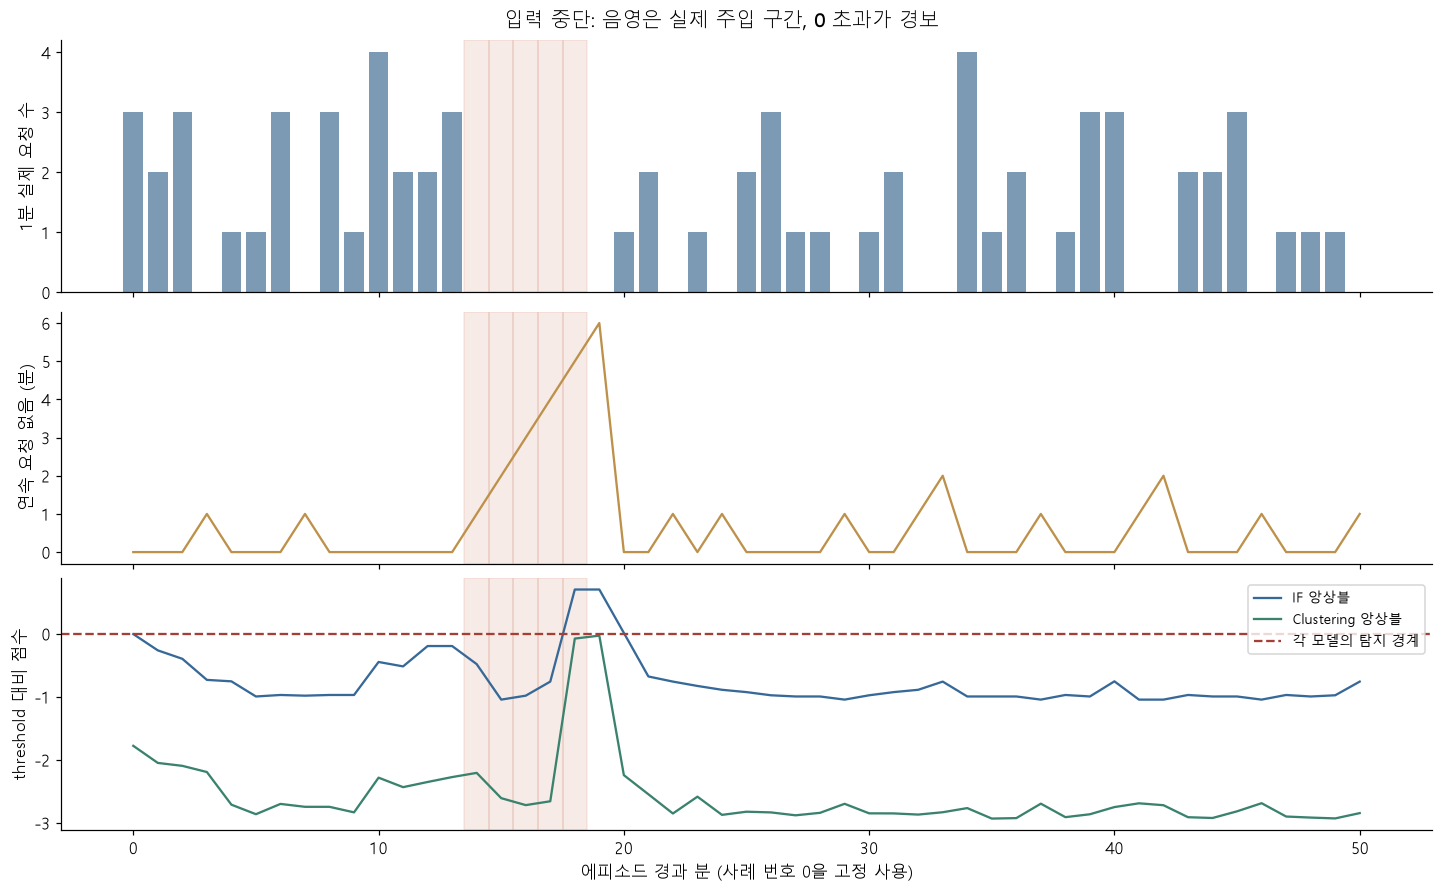

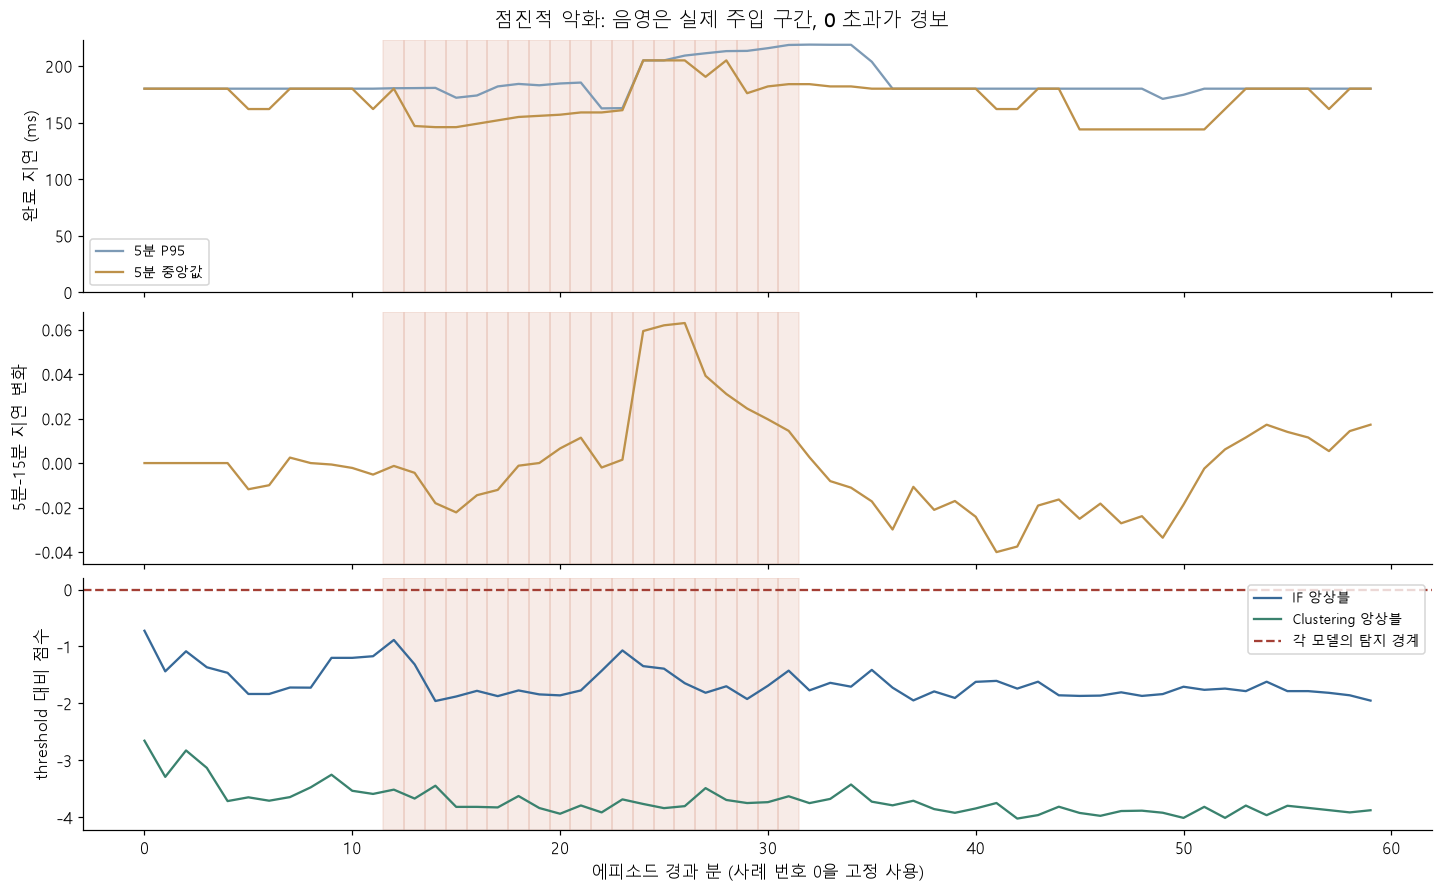

In [16]:
report.timeline('input_stop',0); plt.show()
report.timeline('gradual_degradation',0); plt.show()

## 10. 이벤트 단위 결과와 Hard 한계

Event Recall은 주입 구간 중 한 번 이상 탐지한 이벤트 비중이다. 앞의 분 단위 Recall과 다르다.
Hard에서 6가지 중 일부만 찾은 것과 **6가지 모두 찾은 것**을 분리한다. 사례에 한 번만 경보가 떠도 모든 이상을 찾았다고 부풀리지 않는다.

In [17]:
display(report.event_table(s))
hard=next(d for d in s['datasets'] if d['dataset']=='mixed_hard')
display(pd.DataFrame([{'모델':report.LABELS[i], 'Hard 6종 모두 탐지 (%)':hard['events']['all_six_recall'][m]*100,
                       '정상 사례에서 한번 이상 경보 (%)':hard['events']['normal_case_false_alarm_rate'][m]*100}
                      for i,m in enumerate(METHODS)]).round(2))

,평가셋,이상 유형,모델,Event Recall (%),탐지 이벤트,전체 이벤트,첫 탐지 지연(초)
0,개별 지연,개별 지연,IF,21.40,1070,5000,60.0
1,개별 지연,개별 지연,Clustering,18.12,906,5000,60.0
2,집단 지연,집단 지연,IF,5.96,298,5000,300.0
3,집단 지연,집단 지연,Clustering,90.28,4514,5000,120.0
4,컬럼 관계,컬럼 관계,IF,10.46,523,5000,60.0
5,컬럼 관계,컬럼 관계,Clustering,10.82,541,5000,60.0
6,시간대 폭주,시간대 폭주,IF,63.72,3186,5000,120.0
7,시간대 폭주,시간대 폭주,Clustering,51.36,2568,5000,180.0
8,입력 중단,입력 중단,IF,95.08,4754,5000,300.0
9,입력 중단,입력 중단,Clustering,82.88,4144,5000,300.0


,모델,Hard 6종 모두 탐지 (%),정상 사례에서 한번 이상 경보 (%)
0,IF 전체,0.0,77.0
1,IF Adapter,0.0,84.1
2,IF 앙상블,0.0,79.4
3,Clustering 전체,0.0,7.4
4,Clustering Adapter,0.0,17.4
5,Clustering 앙상블,0.4,33.0


## 11. 구현과 다음 판단

새 후보 모델은 `reports/model_improvement_v4/models_v4.joblib`에 피처 인코더·조건부 정상 참고값·전체/Adapter 모델·보정/threshold를 함께 저장했다.
기존 `process_if_v1.joblib`와 기존 v2 모델은 자동 교체하지 않았다. 운영 모델 선택은 확인 집단·실제 로그 오탐 검증 후 결정해야 한다.
`inference.py`는 hash로 검증한 모델을 불러오는 backend 연결 인터페이스다. 기존 하드 룰을 선행하고, Process를 집단별 상태/분 단위 창으로 만든 뒤 모델을 호출한다.
입력 중단은 로그가 안 들어와도 실행되는 스케줄러, 정상 수집기 상태 확인, 업무별 기대 트래픽이 필요하다.

아래 결과는 합성 벤치마크에서의 개선/역할 차이다. 실제 정상 시간대 이력, 더 다양한 원본 템플릿, 미지 Adapter 홀드아웃, 실장애 정답으로 재검증해야 한다.
모델은 STATUS=S 정상 후보에 맞춘 것이며 H/Z/N/P 정상 여부를 이 결과로 확정할 수 없다.

In [18]:
display(Markdown('\n'.join('- '+x for x in s['protocol']['limitations'])))
display(Markdown(f"선택 모델 크기: **{(OUTPUT/'models_v4.joblib').stat().st_size/1024/1024:.2f} MiB**. "
                 f"전문 모델 수: 알고리즘별 **{sum(x['expert_available'] for x in s['support'])}개**, 전체 모델 1개씩."))

- Adaptive v4 design after v3; new confirmation episodes share source pool/generator.
- Original benchmark already examined; not a fresh blind external test.
- Not full source-data training; compact normal archive and independent replays.
- Traffic prior is synthetic, not a learned real operational baseline.
- No automatic v1 production replacement. Hard rules unchanged.
- S does not certify incident-free real source workflows.

선택 모델 크기: **7.67 MiB**. 전문 모델 수: 알고리즘별 **5개**, 전체 모델 1개씩.

## 참고 논문·문서와 적용 범위

| 자료 | 이번 구현에 적용한 내용 | 적용하지 않은 내용 |
|---|---|---|
| [Liu, Ting, Zhou (2008), Isolation Forest](https://cs.nju.edu.cn/zhouzh/zhouzh.files/publication/icdm08b.pdf) | 짧은 분리 경로 기반 희귀성, 작은 subsample 크기 비교 | 논문의 성능 수치를 우리 데이터 성능으로 재사용하지 않음 |
| [He, Xu, Deng (2003), Discovering cluster-based local outliers](https://www.sciencedirect.com/science/article/pii/S0167865503000035) | 지역 정상 집단을 고려하는 관점의 참고 | CBLOF 알고리즘/작은 군집 가중치를 그대로 구현하지 않음; 자체 P95 반경 보정 실험 |
| [Kim et al. (ICLR 2022), Towards a Rigorous Evaluation of Time-series Anomaly Detection](https://arxiv.org/abs/2109.05257) | point adjustment 미사용, 분/이벤트 지표 구분 | 단순 탐지 한 번으로 이상 구간 전체를 정답 처리하지 않음 |
| [NIST, EWMA Control Charts](https://www.itl.nist.gov/div898/handbook/pmc/section3/pmc324.htm) | 오래된 관측에 감소 가중치를 두는 변화 추세 피처 | 정규분포·독립 관측 가정의 제어 한계는 적용하지 않음 |
| [scikit-learn, MiniBatchKMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.MiniBatchKMeans.html) | 미니배치 정상 중심 학습, K/초기화 설정 | 중심 거리가 이상확률이라는 주장은 하지 않음 |

피처 뷰, 1/5/15분 조합, count-bin fallback, ensemble 가중치와 정상 오탐 예산은 **이 데이터에 대한 실험 설계**다. 논문이 그 값들을 최적이라고 보증한 것은 아니다.